# LIBS Viewer: loading example

A working end-to-end example for examining Applied Spectra LIBS (`.tdms`) data. Run it from the repository root so `src` is importable. More functions will be added over time; this is the logical starting point.

**Data model**

- `LoadLIBSData(path)` loads a single `.tdms` file or a whole folder. It behaves like a read-only dict: `{file key: LIBSFile}`.
- Each `LIBSFile` holds:
  - `params`: instrument parameters shared by every grid location (Series)
  - `positions`: X/Y/Z stage position per grid location (DataFrame)
  - `spectra`: intensities in counts; index = wavelength (nm), one column per grid location
  - `wavelengths`, `accumulated`: the wavelength axis, and whether the file was acquired with `Accumulate = 1`
- The file layout is assumed to be the Applied Spectra standard (first 31 rows = parameters, then the spectrum). Files that don't match are skipped with a warning.

## Load a folder

Point at a folder and every `.tdms` file in it (case-insensitive) is loaded. Pass `recursive=True` to include subfolders. Keys are paths relative to the folder.

In [ ]:
from src.LIBS.tdms_loader import LoadLIBSData

libs = LoadLIBSData('data/libs_data')            # recursive=True to include subfolders
print(len(libs), 'files')
list(libs.keys())       

6 files


['Ce1 350 new location.tdms',
 'Ce1400.tdms',
 'Ce1_300C.tdms',
 'Ce_Sample2_Temp_300C.tdms',
 'Ce_Sample2_Temp_350C.tdms',
 'Ce_Sample2_Temp_400C.tdms']

## Compare files at a glance

In [3]:
import pandas as pd

pd.DataFrame({
    key: {'grid locations': f.spectra.shape[1],
          'accumulated': f.accumulated,
          'shots': f.params['Number Of Shots'],
          'energy': f.params['Energy']}
    for key, f in libs.items()
}).T

,grid locations,accumulated,shots,energy
Ce1 350 new location.tdms,20,False,10.0,80.0
Ce1400.tdms,20,False,10.0,80.0
Ce1_300C.tdms,20,False,10.0,80.0
Ce_Sample2_Temp_300C.tdms,1,True,5.0,80.0
Ce_Sample2_Temp_350C.tdms,1,True,5.0,80.0
Ce_Sample2_Temp_400C.tdms,10,False,5.0,80.0


## Inspect one file

Index the loader by key to get a `LIBSFile`.

In [4]:
f = libs['Ce_Sample2_Temp_400C.tdms']
f.param_table()

Param                          | Value
-------------------------------+------
Gate Delay (usec)              |   3.5
Accumulate                     |     0
Energy                         |    80
Energy Format                  |     0
Number Of Shots                |     5
Rep Rate                       |     1
Warmup Energy                  |    80
# Of Warmup Shots              |    50
Warmup Rep Rate                |    10
Warmup Shots On/Off            |     1
Gas Type (1)                   |     2
Setpoint (1)                   |     0
Gas Type (2)                   |     1
Setpoint (2)                   |     1
Experiment Velocity            |     1
Experiment Acceleration        |    20
Spot Sizes                     |     0
Pre Ablation Delay (Sec)       |     0
Minimum Experiment Delay (Sec) |     1
Washout Delay (Sec)            |     0
Number Of Experiment Passes    |     1
Reverse Pattern Direction      |     0
Pattern Autofocus              |     0
External Trigger Options 

In [5]:
# Parameters are also available programmatically (repeated names get a (1), (2) suffix)
f.params['Energy'], f.params['Gas Type (1)']

(np.float64(80.0), np.float64(2.0))

In [6]:
# X/Y/Z stage position of each grid location
f.positions

,X Position,Y Position,Z Position
Grid Location # 1-1,50.890640,46.723415,24.159492
Grid Location # 1-2,50.890640,46.723415,24.159492
Grid Location # 1-3,50.890640,46.723415,24.159492
Grid Location # 1-4,50.890640,46.723415,24.159492
Grid Location # 1-5,50.890640,46.723415,24.159492
Grid Location # 2-1,49.391838,47.224613,23.759493
Grid Location # 2-2,49.391838,47.224613,23.759493
Grid Location # 2-3,49.391838,47.224613,23.759493
Grid Location # 2-4,49.391838,47.224613,23.759493
Grid Location # 2-5,49.391838,47.224613,23.759493


In [7]:
# Spectra: wavelength (nm) index, one column per grid location
print(f.spectra.shape, f.wavelengths[0], '-', f.wavelengths[-1], 'nm')
f.spectra.iloc[:5, :3]

(12288, 10) 186.567596 - 1049.74292 nm


,Grid Location # 1-1,Grid Location # 1-2,Grid Location # 1-3
wavelength_nm,,,
186.567596,572.424988,543.599976,533.375
186.638397,516.424988,496.600006,573.375
186.709167,495.424988,491.600006,543.375
186.779938,527.424988,490.600006,534.375
186.850708,516.424988,556.599976,549.375


## Quick look at a spectrum

Plain matplotlib for now; a dedicated plotting module (peak labels, reference lines, zoom windows) will follow.

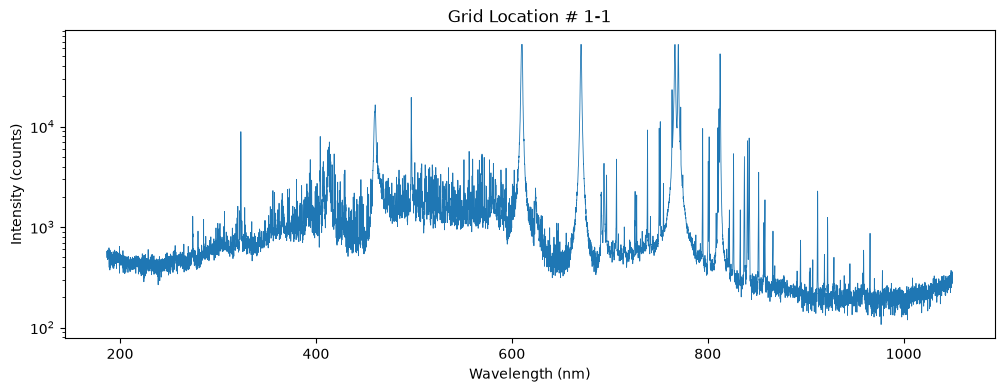

In [8]:
import matplotlib.pyplot as plt

col = f.spectra.columns[0]
ax = f.spectra[col].plot(figsize=(12, 4), lw=0.6, logy=True)
ax.set_xlabel('Wavelength (nm)'); ax.set_ylabel('Intensity (counts)'); ax.set_title(f'{col}');

## Load a single file

A path to one `.tdms` file works too; the key is just the file name.

In [9]:
one = LoadLIBSData(r'data/libs_data/Ce_Sample2_Temp_400C.tdms')
print(list(one.keys()))
one['Ce_Sample2_Temp_400C.tdms'].spectra.shape

['Ce_Sample2_Temp_400C.tdms']


(12288, 10)